<a href="https://colab.research.google.com/github/d005810/ECAA08-Manufatura-Flexivel/blob/main/etapa-03-arvores/Aula%2025%20-%20%C3%81rvores%20de%20Comportamento%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árvores de Comportamento (Behavior Trees) na Supervisão da Célula FMS
### Orquestração Reativa • Preempção de Segurança (`HS-301`) • Gestão de Lotes (`CX-301..303`) • Despacho do `AGV-300`
**Disciplina:** ECAA08 • Engenharia de Controle e Automação & Matemática Discreta  
**Unidade de Processo:** Célula de Manufatura Flexível (FMS) — Setores 100, 200, 300 e 400 (`EXP-400`)  

---

## 🎯 Objetivos do Notebook
1. **Motor de Árvore de Comportamento (BT):** Implementar do zero os nós fundamentais (`Status`, `Selector`, `Sequence`, `Inverter`, `Condition`, `Action`) e o padrão *Blackboard*.
2. **Mapeamento ISA-5.1:** Conectar o *Blackboard* às tags reais da FMS (`HS-301`, `HS-101`, `LS-101`, `M-101`, `XV-101`, `INSP-200`, `XV-201..203`, `US-301..303`, `CX-301..303`, `AGV-300`).
3. **Simulação Multi-Tick de Cenários Reais:** Simular produção contínua, enchimento de caixa ($10$ peças) com missão `RUNNING` do `AGV-300`, falta de peças no silo (`LS-101`) e preempção imediata por E-STOP (`HS-301`).
4. **Auditoria de Segurança (`assert`):** Comprovar que nenhum atuador permanece ligado sob emergência ou caixa cheia.
5. **Visualização Gráfica:** Plotar a estrutura hierárquica da BT no NetworkX e a linha do tempo dos sinais SCADA ao longo dos *ticks*.

In [1]:
from enum import Enum, auto
from typing import Callable, Dict, List, Any, Optional
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

print("✅ Bibliotecas carregadas para simulação da Árvore de Comportamento da FMS.")

✅ Bibliotecas carregadas para simulação da Árvore de Comportamento da FMS.


---
## 1. Implementação do Motor de Behavior Tree e Blackboard SCADA

In [2]:
class Status(Enum):
    SUCCESS = auto()
    FAILURE = auto()
    RUNNING = auto()


class BTNode:
    """Classe base abstrata para todos os nós da Árvore de Comportamento."""
    def __init__(self, name: str):
        self.name = name
        self.last_status: Optional[Status] = None

    def tick(self, bb: Dict[str, Any]) -> Status:
        raise NotImplementedError


class Sequence(BTNode):
    """Executa filhos em ordem; falha ou pausa no primeiro FAILURE ou RUNNING."""
    def __init__(self, name: str, children: List[BTNode]):
        super().__init__(name)
        self.children = children

    def tick(self, bb: Dict[str, Any]) -> Status:
        for child in self.children:
            status = child.tick(bb)
            if status != Status.SUCCESS:
                self.last_status = status
                return status
        self.last_status = Status.SUCCESS
        return Status.SUCCESS


class Selector(BTNode):
    """Executa filhos por prioridade; retorna no primeiro SUCCESS ou RUNNING."""
    def __init__(self, name: str, children: List[BTNode]):
        super().__init__(name)
        self.children = children

    def tick(self, bb: Dict[str, Any]) -> Status:
        for child in self.children:
            status = child.tick(bb)
            if status != Status.FAILURE:
                self.last_status = status
                return status
        self.last_status = Status.FAILURE
        return Status.FAILURE


class Inverter(BTNode):
    """Decorador que inverte SUCCESS <-> FAILURE e mantém RUNNING."""
    def __init__(self, name: str, child: BTNode):
        super().__init__(name)
        self.child = child

    def tick(self, bb: Dict[str, Any]) -> Status:
        status = self.child.tick(bb)
        if status == Status.SUCCESS:
            self.last_status = Status.FAILURE
        elif status == Status.FAILURE:
            self.last_status = Status.SUCCESS
        else:
            self.last_status = Status.RUNNING
        return self.last_status


class Condition(BTNode):
    """Nó folha que avalia um predicado sobre as tags do Blackboard."""
    def __init__(self, name: str, predicate: Callable[[Dict[str, Any]], bool]):
        super().__init__(name)
        self.predicate = predicate

    def tick(self, bb: Dict[str, Any]) -> Status:
        self.last_status = Status.SUCCESS if self.predicate(bb) else Status.FAILURE
        return self.last_status


class Action(BTNode):
    """Nó folha que comanda atuadores e retorna SUCCESS, FAILURE ou RUNNING."""
    def __init__(self, name: str, fn: Callable[[Dict[str, Any]], Status]):
        super().__init__(name)
        self.fn = fn

    def tick(self, bb: Dict[str, Any]) -> Status:
        self.last_status = self.fn(bb)
        return self.last_status

print("✅ Motor de Árvore de Comportamento compilado.")

✅ Motor de Árvore de Comportamento compilado.


---
## 2. Definição do Blackboard (Tags ISA-5.1) e Comportamentos da FMS

Cada caixa (`CX-301`, `CX-302`, `CX-303`) possui capacidade nominal de **$10$ peças**. O túnel `INSP-200` classifica peças nas cores Vermelha (`AS-201`), Verde (`AS-202`) ou Azul (`AS-203`). Caso mais de um sensor de cor ative simultaneamente, ocorre falha de coerência.

In [3]:
CAPACIDADE_CAIXA = 10

def criar_blackboard_inicial() -> Dict[str, Any]:
    return {
        # Setor 100 - Alimentação e Transporte
        "HS-101": 1,          # Comando START ativo
        "LS-101": 0,          # 0 = Silo com peças; 1 = Silo vazio
        "XV-101": 0,          # Pistão de alimentação
        "M-101": 0,           # Esteira principal
        # Setor 200 - Inspeção (peça atual no túnel INSP-200)
        "AS-201": 0,          # Vermelha
        "AS-202": 0,          # Verde
        "AS-203": 0,          # Azul
        "XV-201": 0,          # Desviador 1 (Vermelha)
        "XV-202": 0,          # Desviador 2 (Verde)
        "XV-203": 0,          # Desviador 3 (Azul)
        # Setor 300 - Loteamento e Segurança
        "US-301": 0,          # Contagem CX-301
        "US-302": 0,          # Contagem CX-302
        "US-303": 0,          # Contagem CX-303
        "DESC-304": 0,        # Contagem descarte
        "M-301": 0, "M-302": 0, "M-303": 0,
        "HS-301": 0,          # 1 = E-STOP acionado
        "HS-302": 0,          # 1 = Sinaleiro de alarme/alerta
        # Logística AGV-300
        "AGV-300_estado": "OCIOSO",
        "AGV-300_progresso": 0,
        "modo_operacao": "IDLE",
    }

# --- Funções de Condição e Ação ---
def falha_coerencia_insp(bb: Dict[str, Any]) -> bool:
    return (bb["AS-201"] + bb["AS-202"] + bb["AS-203"]) > 1

def acao_parada_segura(bb: Dict[str, Any]) -> Status:
    bb["M-101"] = 0
    bb["M-301"] = bb["M-302"] = bb["M-303"] = 0
    bb["XV-101"] = 0
    bb["XV-201"] = bb["XV-202"] = bb["XV-203"] = 0
    bb["HS-302"] = 1
    bb["AGV-300_estado"] = "PARADO_EMERGENCIA"
    bb["modo_operacao"] = "EMERGENCIA_TRIP"
    return Status.SUCCESS

def alguma_caixa_cheia(bb: Dict[str, Any]) -> bool:
    return (
        bb["US-301"] >= CAPACIDADE_CAIXA
        or bb["US-302"] >= CAPACIDADE_CAIXA
        or bb["US-303"] >= CAPACIDADE_CAIXA
    )

def acao_bloquear_infeed(bb: Dict[str, Any]) -> Status:
    bb["XV-101"] = 0
    bb["M-101"] = 0
    return Status.SUCCESS

def acao_agv_coletar_lote(bb: Dict[str, Any]) -> Status:
    # Simula missão de 3 ticks para coleta da caixa cheia até EXP-400
    bb["AGV-300_estado"] = "COLETANDO_PARA_EXP400"
    bb["modo_operacao"] = "LOGISTICA_CAIXA_CHEIA"
    bb["AGV-300_progresso"] += 1
    if bb["AGV-300_progresso"] < 3:
        return Status.RUNNING
    # Concluiu transporte: zera a caixa que estava cheia
    for tag in ("US-301", "US-302", "US-303"):
        if bb[tag] >= CAPACIDADE_CAIXA:
            bb[tag] = 0
    bb["AGV-300_progresso"] = 0
    bb["AGV-300_estado"] = "OCIOSO"
    return Status.SUCCESS

def acao_agv_reabastecer_silo(bb: Dict[str, Any]) -> Status:
    bb["XV-101"] = 0
    bb["M-101"] = 0
    bb["HS-302"] = 1
    bb["AGV-300_estado"] = "REABASTECENDO_SILO100"
    bb["modo_operacao"] = "SILO_VAZIO"
    bb["AGV-300_progresso"] += 1
    if bb["AGV-300_progresso"] < 2:
        return Status.RUNNING
    bb["LS-101"] = 0
    bb["HS-302"] = 0
    bb["AGV-300_progresso"] = 0
    bb["AGV-300_estado"] = "OCIOSO"
    return Status.SUCCESS

def acao_ciclo_producao(bb: Dict[str, Any]) -> Status:
    bb["HS-302"] = 0
    bb["M-101"] = 1
    bb["M-301"] = bb["M-302"] = bb["M-303"] = 1
    bb["XV-101"] = 1
    bb["XV-201"] = bb["XV-202"] = bb["XV-203"] = 0
    bb["modo_operacao"] = "PRODUCAO_NOMINAL"

    if bb["AS-201"] == 1:
        bb["XV-201"] = 1
        bb["US-301"] += 1
    elif bb["AS-202"] == 1:
        bb["XV-202"] = 1
        bb["US-302"] += 1
    elif bb["AS-203"] == 1:
        bb["XV-203"] = 1
        bb["US-303"] += 1
    else:
        bb["DESC-304"] += 1
    return Status.SUCCESS

# --- Montagem da Árvore de Comportamento ---
arvore_fms = Selector("ROOT_SCADA", [
    Sequence("SEGURANCA_CRITICA", [
        Selector("COND_FALHA", [
            Condition("HS-301 == 1 (E-STOP)", lambda bb: bb["HS-301"] == 1),
            Condition("Falha Coerencia INSP-200", falha_coerencia_insp),
        ]),
        Action("Parada Segura & Alarme HS-302", acao_parada_segura),
    ]),
    Sequence("GESTAO_CAIXA_CHEIA", [
        Condition("CX-30x >= 10 peças", alguma_caixa_cheia),
        Action("Bloquear XV-101", acao_bloquear_infeed),
        Action("AGV-300 -> EXP-400", acao_agv_coletar_lote),
    ]),
    Sequence("REABASTECIMENTO_SILO", [
        Condition("LS-101 == 1 (Silo Vazio)", lambda bb: bb["LS-101"] == 1),
        Action("AGV-300 -> SILO-100", acao_agv_reabastecer_silo),
    ]),
    Sequence("PRODUCAO_NOMINAL", [
        Condition("HS-101 == 1 (START)", lambda bb: bb["HS-101"] == 1),
        Action("Alimentar, Inspecionar e Triar", acao_ciclo_producao),
    ]),
])

print("✅ Árvore de Comportamento da FMS montada com sucesso.")

✅ Árvore de Comportamento da FMS montada com sucesso.


---
## 3. Simulação Multi-Tick e Auditoria de Invariantes de Segurança (`assert`)

Vamos simular $20$ ciclos de varredura (*ticks*) injetando eventos reais de chão de fábrica:
* **Ticks 1–11:** Peças vermelhas (`AS-201 = 1`) preenchem `CX-301` até $10$ peças; nos ticks seguintes o `AGV-300` entra em `RUNNING` para coletar até `EXP-400`.
* **Ticks 12–14:** Produção retomada com peças verdes (`AS-202 = 1`) e azuis (`AS-203 = 1`).
* **Tick 15:** Acionamento do silo vazio (`LS-101 = 1`).
* **Tick 18:** Acionamento do botão de emergência `HS-301 = 1` (preempção imediata).

In [4]:
bb = criar_blackboard_inicial()
bb["US-301"] = 7  # Inicia com 7 peças vermelhas na CX-301 para atingir 10 rapidamente

historico = []

for tick in range(1, 21):
    # Injeção determinística de leituras de sensores de campo
    bb["AS-201"] = bb["AS-202"] = bb["AS-203"] = 0
    if tick <= 11:
        bb["AS-201"] = 1  # Vermelha
    elif tick in (12, 13):
        bb["AS-202"] = 1  # Verde
    elif tick == 14:
        bb["AS-203"] = 1  # Azul
    elif tick == 15:
        bb["LS-101"] = 1  # Silo vazio
    elif tick in (16, 17):
        bb["AS-201"] = 1
    elif tick == 18:
        bb["HS-301"] = 1  # E-STOP acionado!
    elif tick == 19:
        bb["HS-301"] = 0  # Reset manual de E-STOP
        bb["AS-202"] = 1
    else:
        bb["AS-203"] = 1

    status_raiz = arvore_fms.tick(bb)

    # Auditoria formal de invariantes de segurança
    if bb["HS-301"] == 1:
        assert bb["M-101"] == 0 and bb["XV-101"] == 0, "ERRO CRÍTICO: Atuador ligado durante E-STOP!"
        assert bb["HS-302"] == 1, "ERRO CRÍTICO: Sinaleiro HS-302 deve estar ativo em E-STOP!"
    if bb["AGV-300_estado"] == "COLETANDO_PARA_EXP400":
        assert bb["XV-101"] == 0, "ERRO CRÍTICO: Infeed deve ficar bloqueado durante coleta do AGV!"

    historico.append({
        "Tick": tick,
        "Status_Raiz": status_raiz.name,
        "Modo": bb["modo_operacao"],
        "M-101": bb["M-101"],
        "XV-101": bb["XV-101"],
        "US-301": bb["US-301"],
        "US-302": bb["US-302"],
        "US-303": bb["US-303"],
        "HS-301": bb["HS-301"],
        "HS-302": bb["HS-302"],
        "AGV-300": bb["AGV-300_estado"],
    })

df_hist = pd.DataFrame(historico)
print("✅ Todos os invariantes de segurança validados com sucesso!")
df_hist

✅ Todos os invariantes de segurança validados com sucesso!


,Tick,Status_Raiz,Modo,M-101,XV-101,US-301,US-302,US-303,HS-301,HS-302,AGV-300
0,1,SUCCESS,PRODUCAO_NOMINAL,1,1,8,0,0,0,0,OCIOSO
1,2,SUCCESS,PRODUCAO_NOMINAL,1,1,9,0,0,0,0,OCIOSO
2,3,SUCCESS,PRODUCAO_NOMINAL,1,1,10,0,0,0,0,OCIOSO
3,4,RUNNING,LOGISTICA_CAIXA_CHEIA,0,0,10,0,0,0,0,COLETANDO_PARA_EXP400
4,5,RUNNING,LOGISTICA_CAIXA_CHEIA,0,0,10,0,0,0,0,COLETANDO_PARA_EXP400
5,6,SUCCESS,LOGISTICA_CAIXA_CHEIA,0,0,0,0,0,0,0,OCIOSO
6,7,SUCCESS,PRODUCAO_NOMINAL,1,1,1,0,0,0,0,OCIOSO
7,8,SUCCESS,PRODUCAO_NOMINAL,1,1,2,0,0,0,0,OCIOSO
8,9,SUCCESS,PRODUCAO_NOMINAL,1,1,3,0,0,0,0,OCIOSO
9,10,SUCCESS,PRODUCAO_NOMINAL,1,1,4,0,0,0,0,OCIOSO


---
## 4. Visualização da Árvore de Comportamento e Linha do Tempo SCADA

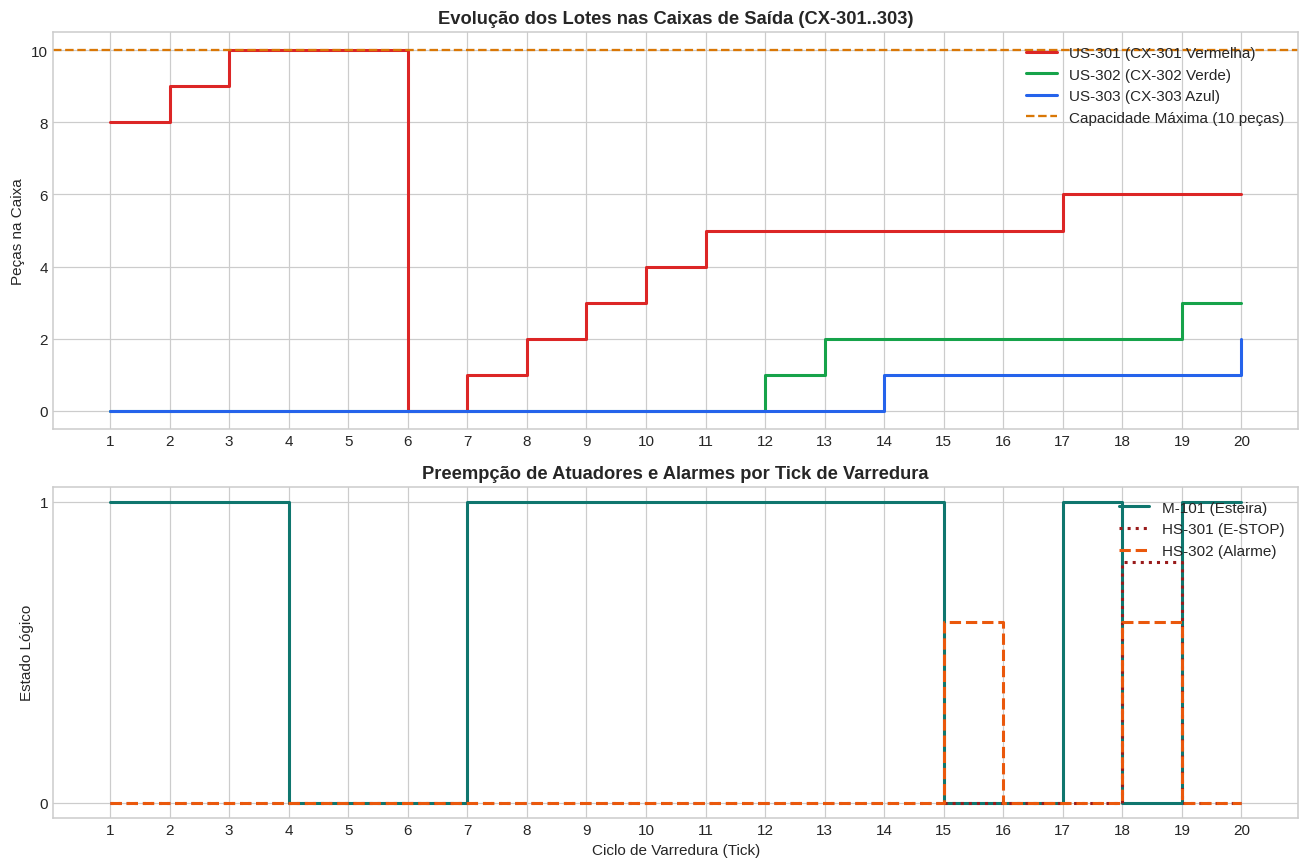

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [1.2, 1]})

# Gráfico 1: Contadores das caixas e estado do motor M-101 / Alarme HS-302
ax1.step(df_hist["Tick"], df_hist["US-301"], where="post", label="US-301 (CX-301 Vermelha)", color="#dc2626", linewidth=2)
ax1.step(df_hist["Tick"], df_hist["US-302"], where="post", label="US-302 (CX-302 Verde)", color="#16a34a", linewidth=2)
ax1.step(df_hist["Tick"], df_hist["US-303"], where="post", label="US-303 (CX-303 Azul)", color="#2563eb", linewidth=2)
ax1.axhline(CAPACIDADE_CAIXA, color="#d97706", linestyle="--", label="Capacidade Máxima (10 peças)")
ax1.set_title("Evolução dos Lotes nas Caixas de Saída (CX-301..303)", fontweight="bold")
ax1.set_ylabel("Peças na Caixa")
ax1.set_xticks(df_hist["Tick"])
ax1.legend(loc="upper right")

# Gráfico 2: Sinais discretos M-101, HS-301 (E-STOP) e HS-302 (Alarme)
ax2.step(df_hist["Tick"], df_hist["M-101"], where="post", label="M-101 (Esteira)", color="#0f766e", linewidth=2)
ax2.step(df_hist["Tick"], df_hist["HS-301"] * 0.8, where="post", label="HS-301 (E-STOP)", color="#991b1b", linewidth=2, linestyle=":")
ax2.step(df_hist["Tick"], df_hist["HS-302"] * 0.6, where="post", label="HS-302 (Alarme)", color="#ea580c", linewidth=2, linestyle="--")
ax2.set_title("Preempção de Atuadores e Alarmes por Tick de Varredura", fontweight="bold")
ax2.set_xlabel("Ciclo de Varredura (Tick)")
ax2.set_ylabel("Estado Lógico")
ax2.set_xticks(df_hist["Tick"])
ax2.set_yticks([0, 1])
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

---
## 5. Conclusões de Engenharia

1. **Reatividade sem Explosão de Estados:** A Árvore de Comportamento orquestrou $4$ modos operacionais distintos (Emergência, Caixa Cheia com `AGV-300`, Silo Vazio e Produção Nominal) com apenas $12$ nós modulares.
2. **Preempção Garantida:** No Tick 18, o acionamento de `HS-301` desligou `M-101` e `XV-101` imediatamente e acionou `HS-302`, sem necessidade de programar transições explícitas de saída a partir dos estados de produção ou logística.